# Stoke data analysis - Healthcare dataset

## Questions to be answered

1. At what age, blood sugar level, or BMI does the risk of having a stroke start to jump up significantly?
2. How much higher is a person's stroke risk if they have both high blood pressure and heart disease compared to having just one or neither?
3. Do smoking habits or types of work connect to higher average blood sugar levels or higher BMIs?
4. Are people in certain living situations (like rural vs. urban) or specific groups more likely to have a stroke than others?
5. How do age, blood sugar, and BMI differ on average between people who have had a stroke and people who haven't?

In [1]:
# import all dependencies 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# import dataset 

df = pd.read_csv('healthcare-dataset-stroke-data.csv')

df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB


In [66]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [4]:
df.isnull().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

In [5]:
df['bmi'].sample(10)

4454    22.9
1439    33.1
2484    43.0
4152    28.0
3605     NaN
3461    24.3
5089    16.8
4899    33.2
4764    15.6
212     30.7
Name: bmi, dtype: float64

In [6]:
df.loc[(df['bmi'].isna())]

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
8,27419,Female,59.0,0,0,Yes,Private,Rural,76.15,NaN,Unknown,1
13,8213,Male,78.0,0,1,Yes,Private,Urban,219.84,NaN,Unknown,1
19,25226,Male,57.0,0,1,No,Govt_job,Urban,217.08,NaN,Unknown,1
27,61843,Male,58.0,0,0,Yes,Private,Rural,189.84,NaN,Unknown,1
...,...,...,...,...,...,...,...,...,...,...,...,...
5039,42007,Male,41.0,0,0,No,Private,Rural,70.15,NaN,formerly smoked,0
5048,28788,Male,40.0,0,0,Yes,Private,Urban,191.15,NaN,smokes,0
5093,32235,Female,45.0,1,0,Yes,Govt_job,Rural,95.02,NaN,smokes,0
5099,7293,Male,40.0,0,0,Yes,Private,Rural,83.94,NaN,smokes,0


In [7]:
df.loc[(df['bmi'].isna()) & (df['gender'] == 'Male')].count()

id                   104
gender               104
age                  104
hypertension         104
heart_disease        104
ever_married         104
work_type            104
Residence_type       104
avg_glucose_level    104
bmi                    0
smoking_status       104
stroke               104
dtype: int64

In [8]:
df.loc[(df['bmi'].isna()) & (df['gender'] == 'Female')].count()

id                   97
gender               97
age                  97
hypertension         97
heart_disease        97
ever_married         97
work_type            97
Residence_type       97
avg_glucose_level    97
bmi                   0
smoking_status       97
stroke               97
dtype: int64

In [9]:
df_new = df.dropna(subset=["bmi"])

df_new = df_new[df_new['gender'] != 'Other']

df_new = df_new.reset_index(drop=True)



df_new.info()

<class 'pandas.DataFrame'>
RangeIndex: 4908 entries, 0 to 4907
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 4908 non-null   int64  
 1   gender             4908 non-null   str    
 2   age                4908 non-null   float64
 3   hypertension       4908 non-null   int64  
 4   heart_disease      4908 non-null   int64  
 5   ever_married       4908 non-null   str    
 6   work_type          4908 non-null   str    
 7   Residence_type     4908 non-null   str    
 8   avg_glucose_level  4908 non-null   float64
 9   bmi                4908 non-null   float64
 10  smoking_status     4908 non-null   str    
 11  stroke             4908 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 460.3 KB


In [10]:
df_new.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
2,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
3,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
4,56669,Male,81.0,0,0,Yes,Private,Urban,186.21,29.0,formerly smoked,1


In [11]:
df_new.nunique()

id                   4908
gender                  2
age                   104
hypertension            2
heart_disease           2
ever_married            2
work_type               5
Residence_type          2
avg_glucose_level    3851
bmi                   418
smoking_status          4
stroke                  2
dtype: int64

In [12]:
df.loc[(df['gender'] == 'Other')].count()

id                   1
gender               1
age                  1
hypertension         1
heart_disease        1
ever_married         1
work_type            1
Residence_type       1
avg_glucose_level    1
bmi                  1
smoking_status       1
stroke               1
dtype: int64

In [13]:
# changing redisence_type to binary and ever_married and gender

df_new['Residence_type'] = df_new['Residence_type'].map({'Urban': 1, 'Rural':0})

df_new['ever_married'] = df_new['ever_married'].map({'Yes': 1, 'No':0})

df_new['gender'] = df_new['gender'].map({'Male': 1, 'Female':0})

In [14]:
df_new.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,1,67.0,0,1,1,Private,1,228.69,36.6,formerly smoked,1
1,31112,1,80.0,0,1,1,Private,0,105.92,32.5,never smoked,1
2,60182,0,49.0,0,0,1,Private,1,171.23,34.4,smokes,1
3,1665,0,79.0,1,0,1,Self-employed,0,174.12,24.0,never smoked,1
4,56669,1,81.0,0,0,1,Private,1,186.21,29.0,formerly smoked,1


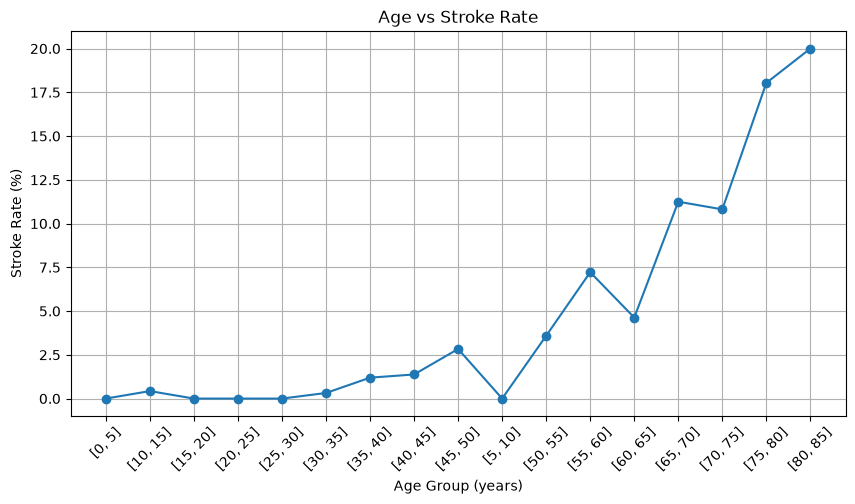

In [15]:
# data needed for question 1 - age, blood sugar, and bmi, y axis stroke

df_new['AgeGroup'] = pd.cut(df_new['age'], bins=range(0, 101, 5))

df_new['AgeGroup'] = df_new['AgeGroup'].astype(str).str.replace('(', '[', regex=False)

age_stroke = df_new.groupby('AgeGroup', observed=True)['stroke'].mean() * 100

plt.figure(figsize=(10, 5))

plt.plot(age_stroke.index.astype(str), age_stroke.values, marker='o')

plt.title('Age vs Stroke Rate')
plt.xlabel('Age Group (years)')
plt.ylabel('Stroke Rate (%)')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()



In [16]:
df_new['avg_glucose_level'].describe()

count    4908.000000
mean      105.297402
std        44.425550
min        55.120000
25%        77.067500
50%        91.680000
75%       113.495000
max       271.740000
Name: avg_glucose_level, dtype: float64

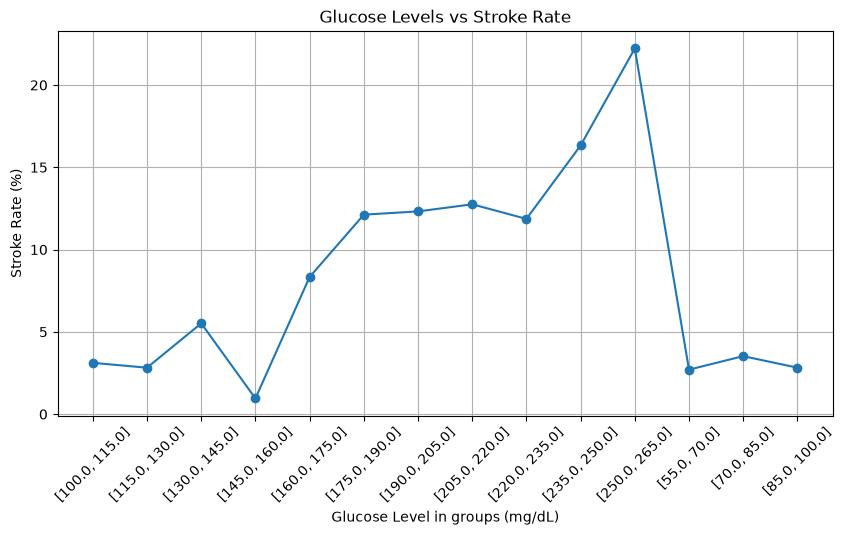

In [17]:
df_new['GlucGroup'] = pd.cut(df_new['avg_glucose_level'], bins=range(55, 275, 15))

df_new['GlucGroup'] = df_new['GlucGroup'].astype(str).str.replace('(', '[', regex=False)

gluc_stroke = df_new.groupby('GlucGroup', observed=True)['stroke'].mean() * 100

plt.figure(figsize=(10, 5))

plt.plot(gluc_stroke.index.astype(str), gluc_stroke.values, marker='o')

plt.title('Glucose Levels vs Stroke Rate')
plt.xlabel('Glucose Level in groups (mg/dL)')
plt.ylabel('Stroke Rate (%)')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()


In [18]:
df_new['bmi'].describe()

count    4908.00000
mean       28.89456
std         7.85432
min        10.30000
25%        23.50000
50%        28.10000
75%        33.10000
max        97.60000
Name: bmi, dtype: float64

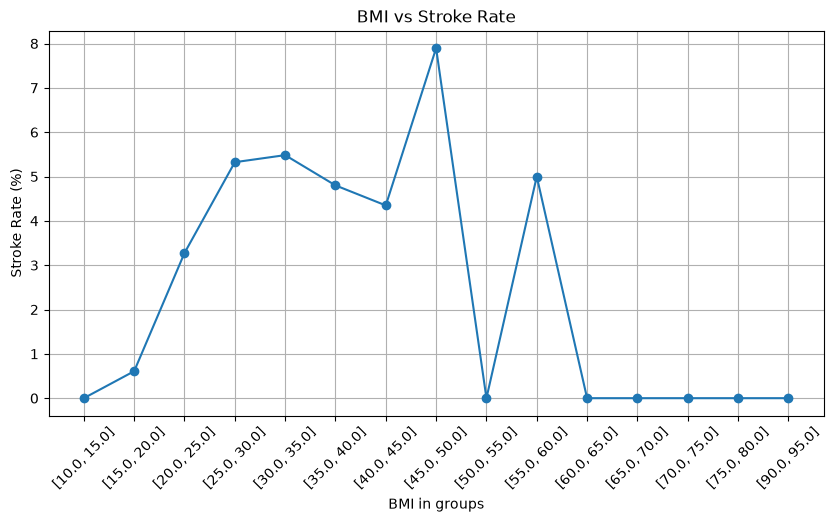

In [19]:
df_new['BMIGroup'] = pd.cut(df_new['bmi'], bins=range(10, 100, 5))

df_new['BMIGroup'] = df_new['BMIGroup'].astype(str).str.replace('(', '[', regex=False)

bmi_stroke = df_new.groupby('BMIGroup', observed=True)['stroke'].mean() * 100

plt.figure(figsize=(10, 5))

plt.plot(bmi_stroke.index.astype(str), bmi_stroke.values, marker='o')

plt.title('BMI vs Stroke Rate')
plt.xlabel('BMI in groups')
plt.ylabel('Stroke Rate (%)')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

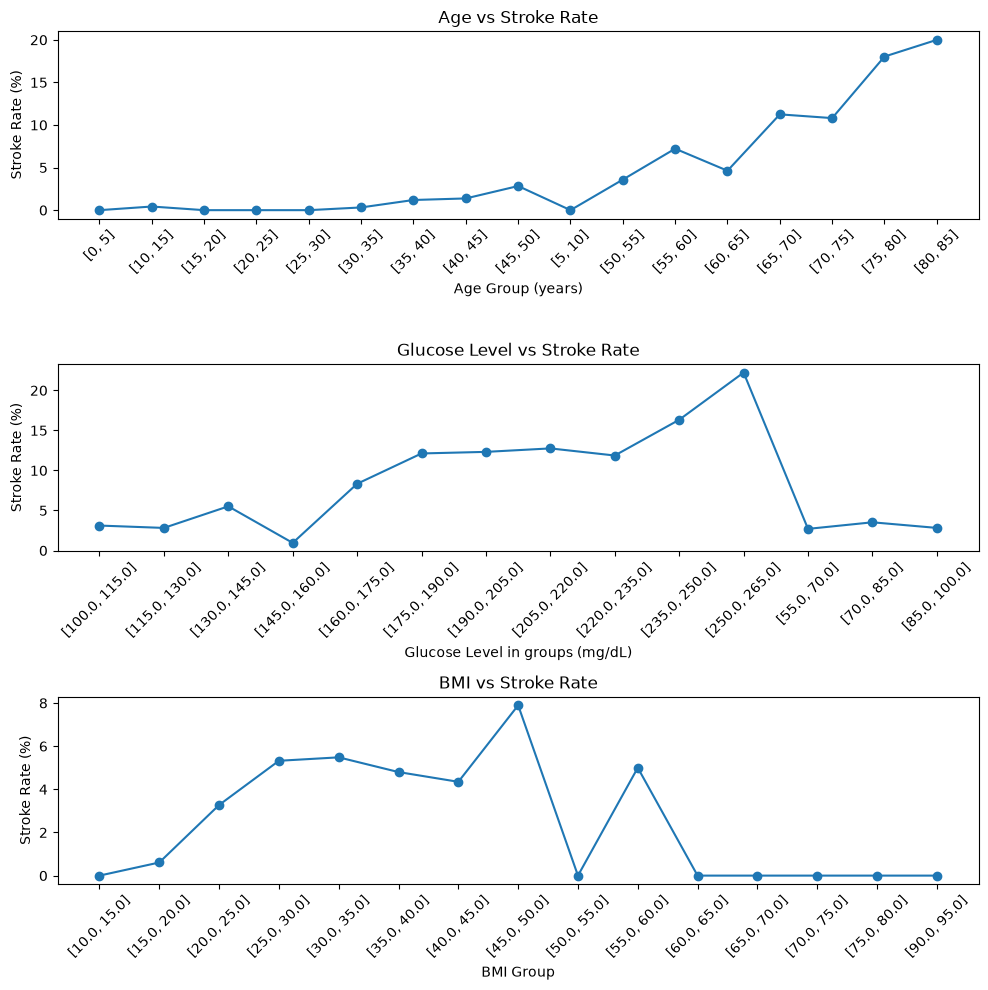

In [20]:
fig, axes = plt.subplots(3,1, figsize=(10, 10))


axes = axes.flatten()

axes[0].plot(age_stroke.index.astype(str), age_stroke.values, marker='o')
axes[0].set_title('Age vs Stroke Rate')
axes[0].set_xlabel('Age Group (years)')
axes[0].set_ylabel('Stroke Rate (%)')
axes[0].tick_params(axis="x", labelrotation=45)


axes[1].plot(gluc_stroke.index.astype(str), gluc_stroke.values, marker='o')
axes[1].set_title('Glucose Level vs Stroke Rate')
axes[1].set_xlabel('Glucose Level in groups (mg/dL)')
axes[1].set_ylabel('Stroke Rate (%)')
axes[1].tick_params(axis="x", labelrotation=45)

axes[2].plot(bmi_stroke.index.astype(str), bmi_stroke.values, marker='o')
axes[2].set_title('BMI vs Stroke Rate')
axes[2].set_xlabel('BMI Group')
axes[2].set_ylabel('Stroke Rate (%)')
axes[2].tick_params(axis="x", labelrotation=45)

plt.tight_layout()
plt.show()


## How much higher is a person's stroke risk if they have both high blood pressure and heart disease compared to having just one or neither?

In [21]:
df_new.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke,AgeGroup,GlucGroup,BMIGroup
0,9046,1,67.0,0,1,1,Private,1,228.69,36.6,formerly smoked,1,"[65, 70]","[220.0, 235.0]","[35.0, 40.0]"
1,31112,1,80.0,0,1,1,Private,0,105.92,32.5,never smoked,1,"[75, 80]","[100.0, 115.0]","[30.0, 35.0]"
2,60182,0,49.0,0,0,1,Private,1,171.23,34.4,smokes,1,"[45, 50]","[160.0, 175.0]","[30.0, 35.0]"
3,1665,0,79.0,1,0,1,Self-employed,0,174.12,24.0,never smoked,1,"[75, 80]","[160.0, 175.0]","[20.0, 25.0]"
4,56669,1,81.0,0,0,1,Private,1,186.21,29.0,formerly smoked,1,"[80, 85]","[175.0, 190.0]","[25.0, 30.0]"


In [22]:
#Combined health status categories (e.g., "Neither", "Hypertension Only", "Heart Disease Only", "Both")



hyper_only = (df_new[df_new['hypertension'] == 1])

percent_hyper = (hyper_only['stroke'].sum() / df_new['stroke'].sum()) * 100

print(percent_hyper)

heart_disease_only = (df_new[df_new['heart_disease'] == 1])

percent_heart = (heart_disease_only['stroke'].sum() / df_new['stroke'].sum()) * 100

print(percent_heart)

both_hyper_heart = (df_new[(df_new['heart_disease'] == 1) & (df_new['hypertension'] == 1)])

percent_both = (both_hyper_heart['stroke'].sum() / df_new['stroke'].sum()) * 100

print(percent_both)

neither = 100 - (percent_hyper + percent_heart)

print(neither)



28.708133971291865
19.138755980861244
5.263157894736842
52.153110047846894


<Figure size 1000x500 with 0 Axes>

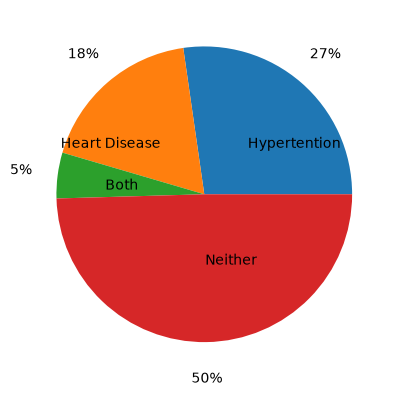

In [23]:
plt.figure(figsize=(10,5))

labels = ['Hypertention', 'Heart Disease', 'Both', 'Neither']

lst = [percent_hyper,percent_heart,percent_both, neither]

fig, ax = plt.subplots()
ax.pie(lst, labels=labels, autopct='%.0f%%',
       pctdistance=1.25, labeldistance=.45)

<Figure size 1000x500 with 0 Axes>

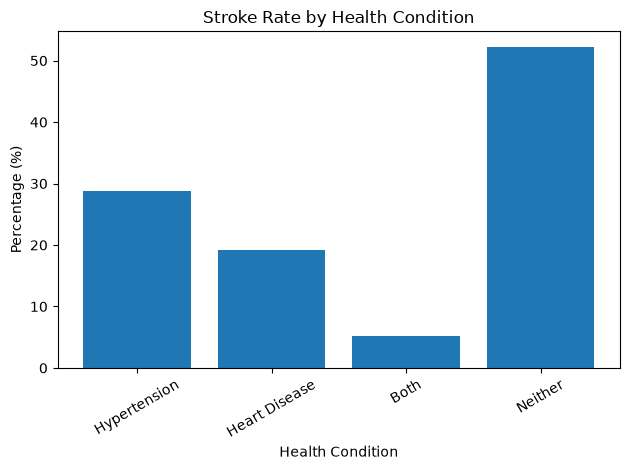

In [36]:
plt.figure(figsize=(10, 5))

labels = ['Hypertension', 'Heart Disease', 'Both', 'Neither']

lst = [percent_hyper, percent_heart, percent_both, neither]

fig, ax = plt.subplots()

ax.bar(labels, lst)

ax.set_title('Stroke Rate by Health Condition')
ax.set_xlabel('Health Condition')
ax.set_ylabel('Percentage (%)')

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Do smoking habits or types of work connect to higher average blood sugar levels or higher BMIs?

In [24]:
df['smoking_status'].unique()

<StringArray>
['formerly smoked', 'never smoked', 'smokes', 'Unknown']
Length: 4, dtype: str

In [25]:
df['work_type'].unique()

<StringArray>
['Private', 'Self-employed', 'Govt_job', 'children', 'Never_worked']
Length: 5, dtype: str

In [26]:
smoke = df_new[df_new['stroke'] == 1]

smoking = smoke.groupby('smoking_status').size()

no_stroke = df_new[df_new['stroke'] == 0]

no_strokeing = no_stroke.groupby('smoking_status').size()

total_grouped = df_new.groupby('smoking_status').size()

count = (df_new['smoking_status']).count()

print(smoking)
print(no_strokeing)

print(total_grouped)

smoking_status
Unknown            29
formerly smoked    57
never smoked       84
smokes             39
dtype: int64
smoking_status
Unknown            1454
formerly smoked     779
never smoked       1768
smokes              698
dtype: int64
smoking_status
Unknown            1483
formerly smoked     836
never smoked       1852
smokes              737
dtype: int64


In [29]:
smoking_precent = (smoking.values / total_grouped.values) * 100

no_stroke_precent = (no_strokeing.values / total_grouped.values) * 100

no_stroke_precent

array([98.04450438, 93.18181818, 95.46436285, 94.7082768 ])

<BarContainer object of 4 artists>

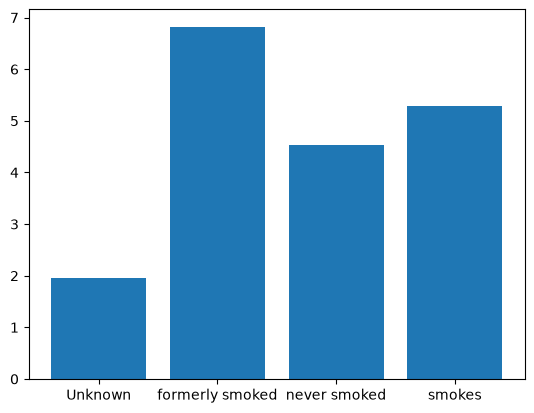

In [35]:
plt.bar(no_strokeing.index, smoking_precent)

In [31]:
smoking_stats = df_new.groupby('smoking_status')[['avg_glucose_level', 'bmi']].mean()
work_stats = df_new.groupby('work_type')[['avg_glucose_level', 'bmi']].mean()

print(smoking_stats)
print(work_stats)

                 avg_glucose_level        bmi
smoking_status                               
Unknown                  98.335927  25.666352
formerly smoked         112.543038  30.757177
never smoked            107.136215  29.982559
smokes                  106.465699  30.543555
               avg_glucose_level        bmi
work_type                                  
Govt_job              107.356825  30.522063
Never_worked           96.042727  25.545455
Private               105.647591  30.307438
Self-employed         112.389161  30.211871
children               94.009806  20.038003


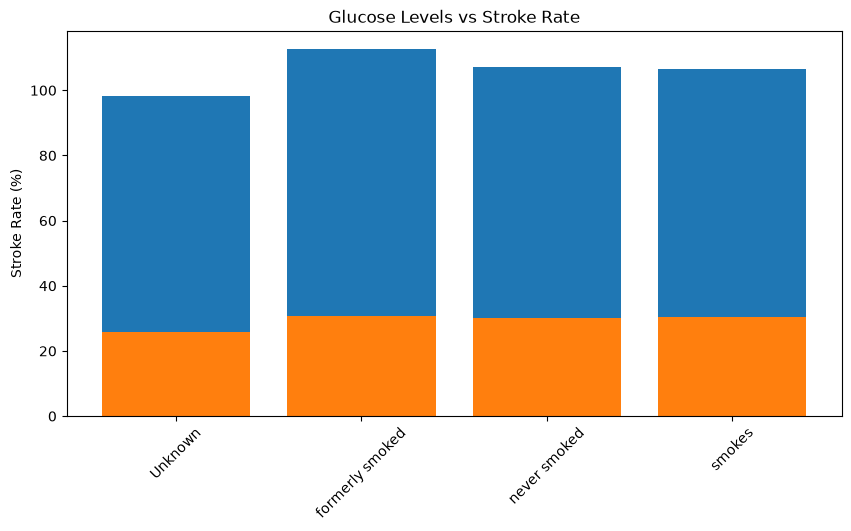

In [32]:
plt.figure(figsize=(10,5))

plt.bar(smoking_stats.index, smoking_stats['avg_glucose_level'])
plt.bar(smoking_stats.index, smoking_stats['bmi'])
#plt.bar(work_stats.index, work_stats['avg_glucose_level'])
#plt.bar(work_stats.index, work_stats['bmi'])
plt.title('Glucose Levels vs Stroke Rate')

plt.ylabel('Stroke Rate (%)')
plt.xticks(rotation=45)

plt.show()

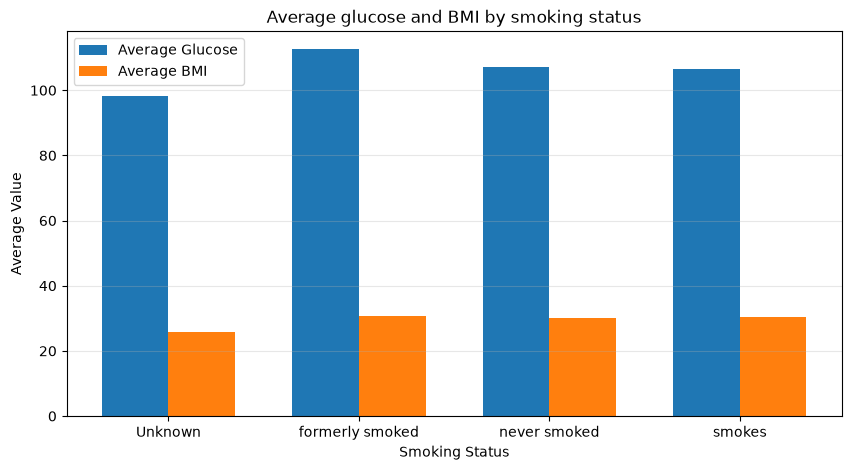

In [33]:
plt.figure(figsize=(10, 5))

x = np.arange(len(smoking_stats.index))
width = 0.35

plt.bar(x - width/2, smoking_stats['avg_glucose_level'],
        width, label='Average Glucose')

plt.bar(x + width/2, smoking_stats['bmi'],
        width, label='Average BMI')

plt.xticks(x, smoking_stats.index)

plt.title('Average glucose and BMI by smoking status')
plt.xlabel('Smoking Status')
plt.ylabel('Average Value')
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.show()

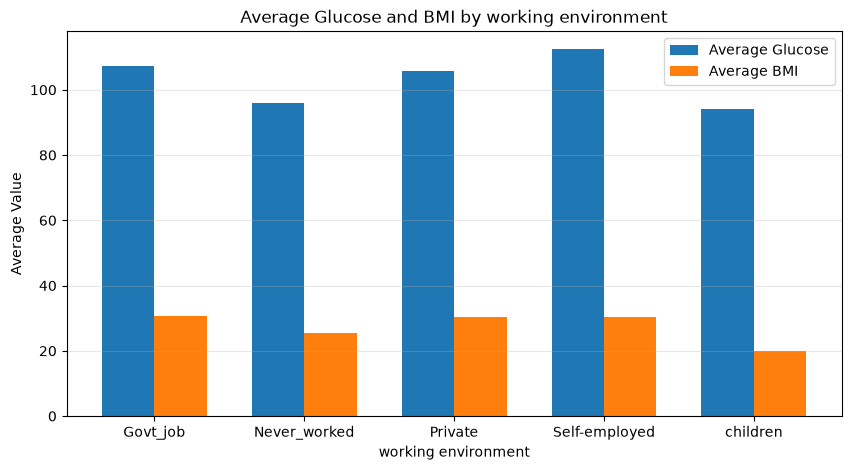

In [34]:
plt.figure(figsize=(10, 5))

x = np.arange(len(work_stats.index))
width = 0.35

plt.bar(x - width/2, work_stats['avg_glucose_level'],
        width, label='Average Glucose')

plt.bar(x + width/2, work_stats['bmi'],
        width, label='Average BMI')

plt.xticks(x, work_stats.index)

plt.title('Average Glucose and BMI by working environment')
plt.xlabel('working environment')
plt.ylabel('Average Value')
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.show()

# 4. Are people in certain living situations (like rural vs. urban) more likely to have a stroke than others?

In [37]:
df_new.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke,AgeGroup,GlucGroup,BMIGroup
0,9046,1,67.0,0,1,1,Private,1,228.69,36.6,formerly smoked,1,"[65, 70]","[220.0, 235.0]","[35.0, 40.0]"
1,31112,1,80.0,0,1,1,Private,0,105.92,32.5,never smoked,1,"[75, 80]","[100.0, 115.0]","[30.0, 35.0]"
2,60182,0,49.0,0,0,1,Private,1,171.23,34.4,smokes,1,"[45, 50]","[160.0, 175.0]","[30.0, 35.0]"
3,1665,0,79.0,1,0,1,Self-employed,0,174.12,24.0,never smoked,1,"[75, 80]","[160.0, 175.0]","[20.0, 25.0]"
4,56669,1,81.0,0,0,1,Private,1,186.21,29.0,formerly smoked,1,"[80, 85]","[175.0, 190.0]","[25.0, 30.0]"


In [45]:
stroke = df_new[df_new['stroke'] == 1]
residential_stroke_stats = stroke.groupby('Residence_type')[['stroke']].size()

stroke_na = df_new[df_new['stroke'] == 0]
residential_NS_stats = stroke_na.groupby('Residence_type')[['stroke']].size()

print(residential_stroke_stats)

print(residential_NS_stats)


Residence_type
0    100
1    109
dtype: int64
Residence_type
0    2318
1    2381
dtype: int64


In [49]:
percent_total_stroke = ((residential_stroke_stats.values) / (residential_stroke_stats.values + residential_NS_stats.values) * 100)

percent_total_stroke

lst = [percent_total_stroke[0],(100 - percent_total_stroke[0])]

lst

[np.float64(4.1356492969396195), np.float64(95.86435070306038)]

<Figure size 1000x500 with 0 Axes>

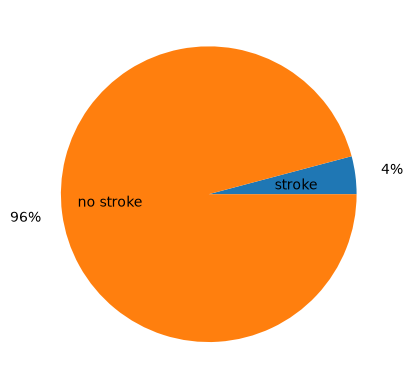

In [50]:
labels = ['stroke', 'no stroke']

plt.figure(figsize=(10,5))


lst = [percent_total_stroke[0],(100 - percent_total_stroke[0])]

fig, ax = plt.subplots()
ax.pie(lst, labels=labels, autopct='%.0f%%',
       pctdistance=1.25, labeldistance=.45)

<Figure size 1000x500 with 0 Axes>

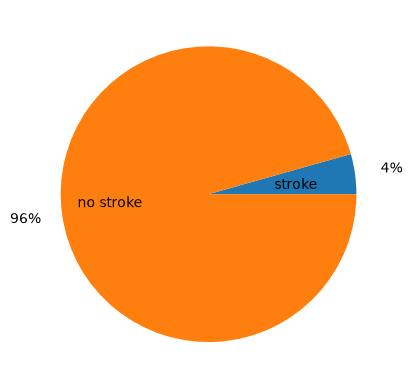

In [51]:
labels = ['stroke', 'no stroke']

plt.figure(figsize=(10,5))


lst = [percent_total_stroke[1],(100 - percent_total_stroke[1])]

fig, ax = plt.subplots()
ax.pie(lst, labels=labels, autopct='%.0f%%',
       pctdistance=1.25, labeldistance=.45)

## 5. How do age, blood sugar, and BMI differ on average between people who have had a stroke and people who haven't?

In [ ]:
stroke_comparison = df_new.groupby('stroke')[['age', 'avg_glucose_level', 'bmi']].mean()

print(stroke_comparison)

              age  avg_glucose_level        bmi
stroke                                         
0       41.763805         103.995367  28.824431
1       67.712919         134.571388  30.471292


In [53]:
stroke_comparison.index = ['No Stroke', 'Stroke']

print(stroke_comparison.round(2))

             age  avg_glucose_level    bmi
No Stroke  41.76             104.00  28.82
Stroke     67.71             134.57  30.47


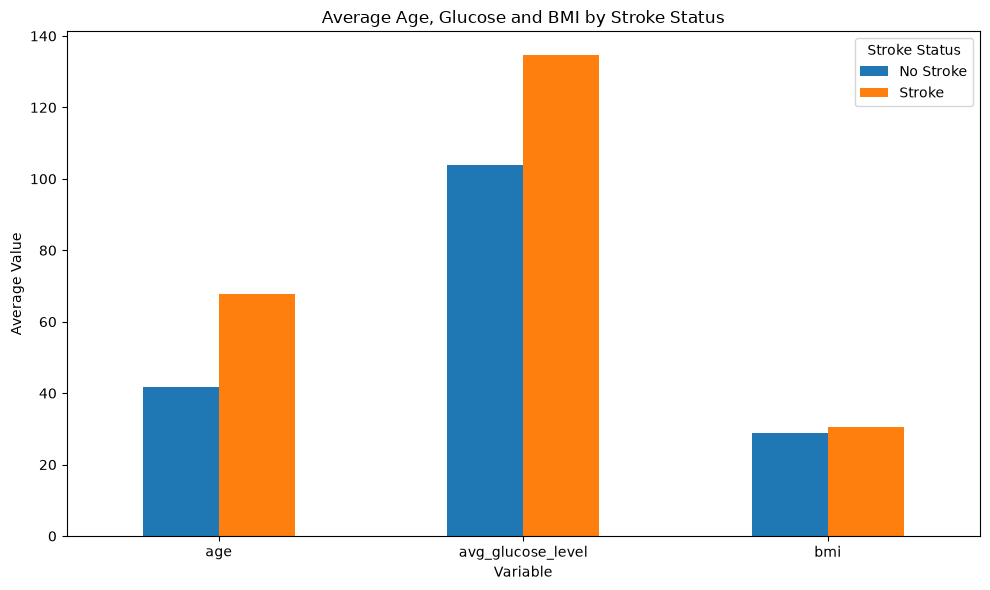

In [65]:
stroke_comparison.T.plot(
    kind='bar',
    figsize=(10, 6)
)
plt.title('Average Age, Glucose and BMI by Stroke Status')
plt.xlabel('Variable')
plt.ylabel('Average Value')
plt.xticks(rotation=0)
plt.legend(title='Stroke Status')
plt.tight_layout()
plt.show()

In [69]:
df_new.columns

Index(['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke', 'AgeGroup', 'GlucGroup', 'BMIGroup'],
      dtype='str')

In [70]:
df_new


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke,AgeGroup,GlucGroup,BMIGroup
0,9046,1,67.0,0,1,1,Private,1,228.69,36.6,formerly smoked,1,"[65, 70]","[220.0, 235.0]","[35.0, 40.0]"
1,31112,1,80.0,0,1,1,Private,0,105.92,32.5,never smoked,1,"[75, 80]","[100.0, 115.0]","[30.0, 35.0]"
2,60182,0,49.0,0,0,1,Private,1,171.23,34.4,smokes,1,"[45, 50]","[160.0, 175.0]","[30.0, 35.0]"
3,1665,0,79.0,1,0,1,Self-employed,0,174.12,24.0,never smoked,1,"[75, 80]","[160.0, 175.0]","[20.0, 25.0]"
4,56669,1,81.0,0,0,1,Private,1,186.21,29.0,formerly smoked,1,"[80, 85]","[175.0, 190.0]","[25.0, 30.0]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4903,14180,0,13.0,0,0,0,children,0,103.08,18.6,Unknown,0,"[10, 15]","[100.0, 115.0]","[15.0, 20.0]"
4904,44873,0,81.0,0,0,1,Self-employed,1,125.20,40.0,never smoked,0,"[80, 85]","[115.0, 130.0]","[35.0, 40.0]"
4905,19723,0,35.0,0,0,1,Self-employed,0,82.99,30.6,never smoked,0,"[30, 35]","[70.0, 85.0]","[30.0, 35.0]"
4906,37544,1,51.0,0,0,1,Private,0,166.29,25.6,formerly smoked,0,"[50, 55]","[160.0, 175.0]","[25.0, 30.0]"


In [71]:
df_new2 = df_new.loc[:, ['id','gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke']]
df_new2

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,1,67.0,0,1,1,Private,1,228.69,36.6,formerly smoked,1
1,31112,1,80.0,0,1,1,Private,0,105.92,32.5,never smoked,1
2,60182,0,49.0,0,0,1,Private,1,171.23,34.4,smokes,1
3,1665,0,79.0,1,0,1,Self-employed,0,174.12,24.0,never smoked,1
4,56669,1,81.0,0,0,1,Private,1,186.21,29.0,formerly smoked,1
...,...,...,...,...,...,...,...,...,...,...,...,...
4903,14180,0,13.0,0,0,0,children,0,103.08,18.6,Unknown,0
4904,44873,0,81.0,0,0,1,Self-employed,1,125.20,40.0,never smoked,0
4905,19723,0,35.0,0,0,1,Self-employed,0,82.99,30.6,never smoked,0
4906,37544,1,51.0,0,0,1,Private,0,166.29,25.6,formerly smoked,0


In [73]:
df_new2.to_csv('stroke_dataset_cleaned.csv')